In [2]:
%pip install -q open3d numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import open3d as o3d
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Open3D version:", o3d.__version__)
print("NumPy version:", np.__version__)
print("Outputs will be saved in:", OUTPUT_DIR.resolve())

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Open3D version: 0.20.0
NumPy version: 2.2.6
Outputs will be saved in: C:\Users\venki\Lab_3_Poisson reconructions\outputs


In [3]:
np.random.seed(42)
n = 5000

phi = np.random.uniform(0, 2 * np.pi, n)
theta = np.random.uniform(0, np.pi, n)

radius = 1.0
x = radius * np.sin(theta) * np.cos(phi)
y = radius * np.sin(theta) * np.sin(phi)
z = radius * np.cos(theta)

points = np.column_stack((x, y, z))

# Add small measurement noise
noise = np.random.normal(0, 0.015, points.shape)
points_noisy = points + noise

pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points_noisy)

print("Number of input points:", len(pcd.points))

Number of input points: 5000


In [4]:
o3d.visualization.draw_geometries(
    [pcd],
    window_name="Input Point Cloud",
    width=900,
    height=700
)

In [5]:
pcd.estimate_normals(
    search_param=o3d.geometry.KDTreeSearchParamHybrid(
        radius=0.15,
        max_nn=30
    )
)

# Make neighboring normals more consistent in orientation
pcd.orient_normals_consistent_tangent_plane(50)

print("Surface normals estimated and oriented.")
print("Number of normals:", len(pcd.normals))

Surface normals estimated and oriented.
Number of normals: 5000


In [12]:
o3d.visualization.draw_geometries(
    [pcd],
    window_name="Point Cloud with Surface Normals",
    point_show_normal=True,
    width=900,
    height=700
)

In [7]:
mesh, densities = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(
    pcd,
    depth=9,
    width=0,
    scale=1.1,
    linear_fit=False
)

print("Poisson reconstruction completed.")
print("Initial mesh vertices:", len(mesh.vertices))
print("Initial mesh triangles:", len(mesh.triangles))

Poisson reconstruction completed.
Initial mesh vertices: 16740
Initial mesh triangles: 33300


Density minimum: 4.359497547149658
Density median: 5.1113502979278564
Density maximum: 7.482461452484131


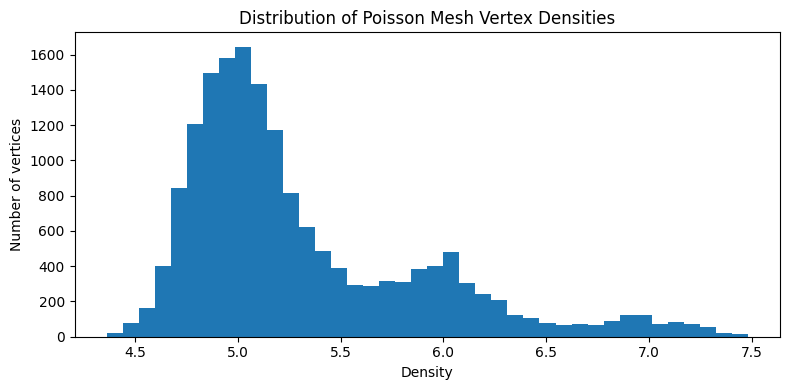

In [8]:
densities = np.asarray(densities)

print("Density minimum:", float(densities.min()))
print("Density median:", float(np.median(densities)))
print("Density maximum:", float(densities.max()))

plt.figure(figsize=(8, 4))
plt.hist(densities, bins=40)
plt.title("Distribution of Poisson Mesh Vertex Densities")
plt.xlabel("Density")
plt.ylabel("Number of vertices")
plt.tight_layout()
plt.show()

In [9]:
density_threshold = np.quantile(densities, 0.02)
vertices_to_remove = densities < density_threshold

mesh.remove_vertices_by_mask(vertices_to_remove)

print("Density threshold (2%):", float(density_threshold))
print("After filtering:")
print("Vertices:", len(mesh.vertices))
print("Triangles:", len(mesh.triangles))

Density threshold (2%): 4.614531660079956
After filtering:
Vertices: 16405
Triangles: 32098


In [10]:
mesh.compute_vertex_normals()

o3d.visualization.draw_geometries(
    [mesh],
    window_name="Poisson Reconstructed Triangle Mesh",
    mesh_show_back_face=True,
    width=900,
    height=700
)

In [11]:
output_file = OUTPUT_DIR / "poisson_reconstructed_mesh.ply"
success = o3d.io.write_triangle_mesh(str(output_file), mesh)

print("Saved successfully:", success)
print("Mesh path:", output_file.resolve())

Saved successfully: True
Mesh path: C:\Users\venki\Lab_3_Poisson reconructions\outputs\poisson_reconstructed_mesh.ply


In [13]:
depth_results = {}

for d in [7, 9, 10]:
    test_mesh, _ = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(
        pcd, depth=d, width=0, scale=1.1, linear_fit=False
    )
    depth_results[d] = (len(test_mesh.vertices), len(test_mesh.triangles))
    print(f"depth={d}: vertices={len(test_mesh.vertices)}, triangles={len(test_mesh.triangles)}")

depth=7: vertices=15526, triangles=30936
depth=9: vertices=16740, triangles=33300
depth=10: vertices=16739, triangles=33298


In [14]:
for d in [7, 9, 10]:
    test_mesh, _ = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(
        pcd, depth=d, width=0, scale=1.1, linear_fit=False
    )
    test_mesh.compute_vertex_normals()
    o3d.visualization.draw_geometries(
        [test_mesh],
        window_name=f"Poisson Mesh - depth {d}",
        mesh_show_back_face=True
    )

In [15]:
for r in [0.08, 0.15, 0.25]:
    test_pcd = o3d.geometry.PointCloud(pcd)
    test_pcd.estimate_normals(
        search_param=o3d.geometry.KDTreeSearchParamHybrid(
            radius=r,
            max_nn=30
        )
    )
    test_pcd.orient_normals_consistent_tangent_plane(50)
    test_mesh, _ = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(
        test_pcd, depth=9, scale=1.1
    )
    print(f"radius={r:.2f}: vertices={len(test_mesh.vertices)}, triangles={len(test_mesh.triangles)}")

radius=0.08: vertices=16838, triangles=33504
radius=0.15: vertices=16740, triangles=33300
radius=0.25: vertices=16744, triangles=33308


In [16]:
# Reconstruct once to get an unfiltered mesh and its density values
mesh_base, density_base = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(
    pcd, depth=9, scale=1.1
)
density_base = np.asarray(density_base)

for q in [0.02, 0.05]:
    mesh_test = o3d.geometry.TriangleMesh(mesh_base)
    threshold = np.quantile(density_base, q)
    mesh_test.remove_vertices_by_mask(density_base < threshold)
    print(
        f"Removed lowest {int(q*100)}%: "
        f"threshold={threshold:.5f}, "
        f"vertices={len(mesh_test.vertices)}, "
        f"triangles={len(mesh_test.triangles)}"
    )

Removed lowest 2%: threshold=4.61453, vertices=16405, triangles=32098
Removed lowest 5%: threshold=4.69083, vertices=15903, triangles=30488
